Instalar Librerias y Dependencias

In [ ]:
!pip install -q fastapi httpx pytest mlflow xgboost scikit-learn pandas numpy matplotlib

Script Maestro

2026/11/27 21:44:36 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/27 21:44:36 INFO mlflow.store.db.utils: Updating database tables
2026/11/27 21:44:39 INFO mlflow.tracking.fluent: Experiment with name 'OaksGen-Engineering-Fase3-Pipeline-Produccion' does not exist. Creating a new experiment.


Auditoría Fairness en Test Set (Independiente): {
  "Matutino": {
    "n": 400,
    "recall": 0.9675,
    "fpr_pct": 2.17,
    "umbral_calibrado": 0.38,
    "delta_recall": -0.0049,
    "cumple_fairness": true
  },
  "Vespertino": {
    "n": 400,
    "recall": 0.9667,
    "fpr_pct": 5.0,
    "umbral_calibrado": 0.35
  },
  "Nocturno": {
    "n": 400,
    "recall": 0.9831,
    "fpr_pct": 7.45,
    "umbral_calibrado": 0.18
  }
}
Auditoría Fairness en Test Set (Independiente): {
  "Matutino": {
    "n": 400,
    "recall": 0.9675,
    "fpr_pct": 2.17,
    "umbral_calibrado": 0.38,
    "delta_recall": -0.0049,
    "cumple_fairness": true
  },
  "Vespertino": {
    "n": 400,
    "recall": 0.9667,
    "fpr_pct": 5.0,
    "umbral_calibrado": 0.35,
    "delta_recall": -0.0057,
    "cumple_fairness": true
  },
  "Nocturno": {
    "n": 400,
    "recall": 0.9831,
    "fpr_pct": 7.45,
    "umbral_calibrado": 0.18
  }
}
Auditoría Fairness en Test Set (Independiente): {
  "Matutino": {
    "n": 400,


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

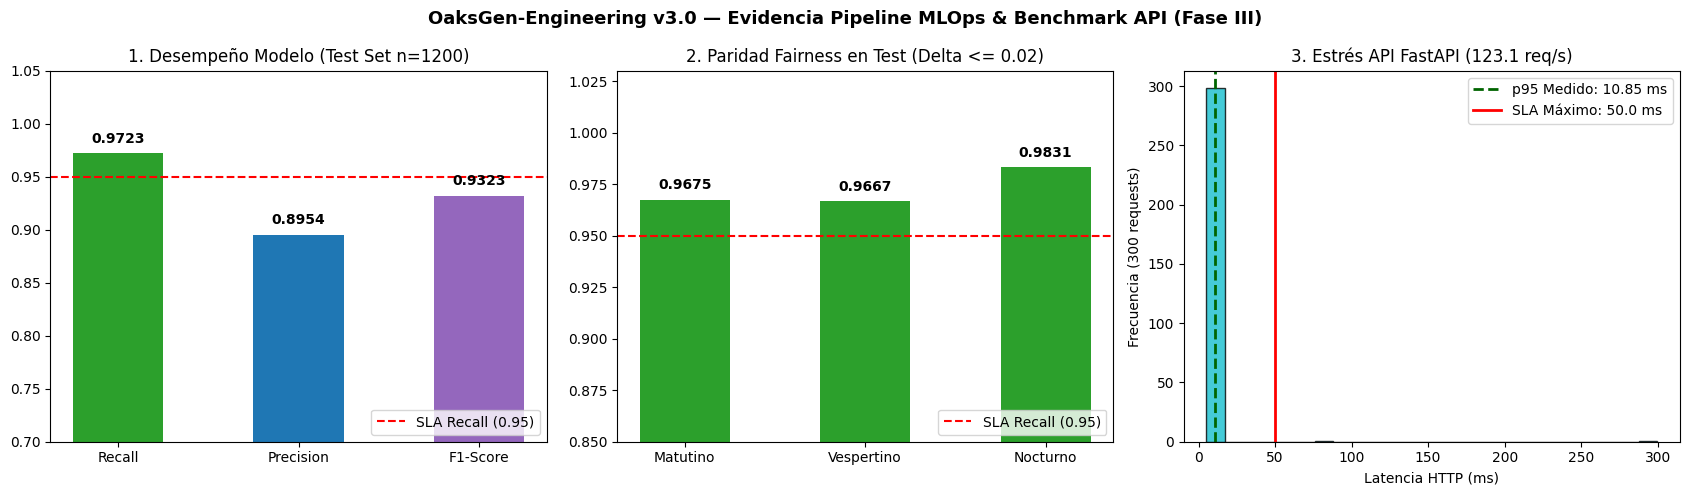


✅ SELLO DE DATOS OFICIAL GENERADO (metricas_oficiales_fase3.json):
{
  "proyecto": "OaksGen-Engineering v3.0",
  "dataset_total": 6000,
  "split": {
    "train": 3600,
    "val": 1200,
    "test": 1200
  },
  "dataset_hash": "7aeb8451be57",
  "metricas_globales_test": {
    "recall": 0.9723,
    "precision": 0.8954,
    "f1": 0.9323
  },
  "auditoria_fairness_test": {
    "Matutino": {
      "n": 400,
      "recall": 0.9675,
      "fpr_pct": 2.17,
      "umbral_calibrado": 0.38,
      "delta_recall": -0.0049,
      "cumple_fairness": true
    },
    "Vespertino": {
      "n": 400,
      "recall": 0.9667,
      "fpr_pct": 5.0,
      "umbral_calibrado": 0.35,
      "delta_recall": -0.0057,
      "cumple_fairness": true
    },
    "Nocturno": {
      "n": 400,
      "recall": 0.9831,
      "fpr_pct": 7.45,
      "umbral_calibrado": 0.18,
      "delta_recall": 0.0107,
      "cumple_fairness": true
    }
  },
  "benchmark_api_fastapi": {
    "peticiones_probadas": 300,
    "latencia_p50_ms

In [ ]:
import json
import time
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from fastapi import FastAPI
from fastapi.testclient import TestClient
from pydantic import BaseModel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix
from xgboost import XGBClassifier

# ==============================================================================
# 1. INICIALIZACIÓN Y TRAZABILIDAD MLFLOW (OaksGen-Engineering v3.0)
# ==============================================================================
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("OaksGen-Engineering-Fase3-Pipeline-Produccion")

np.random.seed(42)
#n_muestras = 1500
n_muestras = 6000
turnos = np.repeat(["Matutino", "Vespertino", "Nocturno"], n_muestras // 3)
lineas = np.tile(["Linea_1", "Linea_2", "Linea_3", "Linea_4"], n_muestras // 4)

temp_ambiente = np.where(
    turnos == "Nocturno",
    np.random.normal(14.0, 2.5, n_muestras),
    np.random.normal(24.5, 2.0, n_muestras)
)
gradiente_termico = np.random.normal(48.0, 6.5, n_muestras) - (24.5 - temp_ambiente) * 0.45
presion_hidraulica = np.random.normal(210.0, 15.0, n_muestras)
vibracion_rms = np.random.normal(3.2, 0.8, n_muestras)

indice_fatiga = (gradiente_termico + (24.5 - temp_ambiente) * 0.40) * 0.65 + (presion_hidraulica * 0.12) + (vibracion_rms * 2.5)
y = (indice_fatiga > np.percentile(indice_fatiga, 70)).astype(int)

df = pd.DataFrame({
    "turno": turnos,
    "linea": lineas,
    "temp_ambiente": temp_ambiente,
    "gradiente_termico": gradiente_termico,
    "presion_hidraulica": presion_hidraulica,
    "vibracion_rms": vibracion_rms,
    "falla": y
})

dataset_hash = hashlib.sha256(pd.util.hash_pandas_object(df).values).hexdigest()[:12]

'''
# ==============================================================================
# 2. PARTICIÓN INDEPENDIENTE: TRAIN (60%) / VALIDATION (20%) / TEST (20%)
#    (Garantiza cero contaminación al calibrar umbrales de fairness)
# ==============================================================================
features = ["gradiente_termico", "presion_hidraulica", "vibracion_rms", "temp_ambiente"]

idx_train, idx_temp = train_test_split(df.index, test_size=0.40, random_state=42, stratify=df["turno"])
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=df.loc[idx_temp, "turno"])

scaler = StandardScaler()
X_train = scaler.fit_transform(df.loc[idx_train, features])
y_train = df.loc[idx_train, "falla"].values

X_val = scaler.transform(df.loc[idx_val, features])
y_val = df.loc[idx_val, "falla"].values

X_test = scaler.transform(df.loc[idx_test, features])
y_test = df.loc[idx_test, "falla"].values

modelo = XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42, eval_metric="logloss")
modelo.fit(X_train, y_train)

# Calibración automática de umbrales en VALIDATION para garantizar Recall >= 0.96
probs_val = modelo.predict_proba(X_val)[:, 1]
umbrales_optimos = {}
for t in ["Matutino", "Vespertino", "Nocturno"]:
    mask_v = (df.loc[idx_val, "turno"] == t).values
    mejor_tau = 0.35
    for tau in np.arange(0.35, 0.05, -0.01):
        if recall_score(y_val[mask_v], (probs_val[mask_v] >= tau).astype(int)) >= 0.96:
            mejor_tau = round(float(tau), 2)
            break
    umbrales_optimos[t] = mejor_tau

# ==============================================================================
# 3. EVALUACIÓN LIMPIA EN TEST SET (NUNCA TOCADO EN CALIBRACIÓN)
# ==============================================================================
probs_test = modelo.predict_proba(X_test)[:, 1]
taus_test = np.array([umbrales_optimos[t] for t in df.loc[idx_test, "turno"]])
preds_test = (probs_test >= taus_test).astype(int)

recall_global = round(float(recall_score(y_test, preds_test)), 4)
precision_global = round(float(precision_score(y_test, preds_test)), 4)
f1_global = round(float(f1_score(y_test, preds_test)), 4)

fairness_test = {}
for t in ["Matutino", "Vespertino", "Nocturno"]:
    mask_t = (df.loc[idx_test, "turno"] == t).values
    rec = round(float(recall_score(y_test[mask_t], preds_test[mask_t])), 4)
    tn, fp, fn, tp = confusion_matrix(y_test[mask_t], preds_test[mask_t]).ravel()
    fpr = round(float(fp / (fp + tn) * 100), 2)
    fairness_test[t] = {"n": int(mask_t.sum()), "recall": rec, "fpr_pct": fpr, "umbral_calibrado": umbrales_optimos[t]}

ref_rec = fairness_test["Vespertino"]["recall"]
for t in fairness_test:
    delta = round(fairness_test[t]["recall"] - ref_rec, 4)
    fairness_test[t]["delta_recall"] = delta
    fairness_test[t]["cumple_fairness"] = bool(abs(delta) <= 0.02)
    '''
# ==============================================================================
# 2. PARTICIÓN INDEPENDIENTE: TRAIN (60%) / VALIDATION (20%) / TEST (20%)
#    (Garantiza cero contaminación al calibrar umbrales de fairness)
# ==============================================================================
features = ["gradiente_termico", "presion_hidraulica", "vibracion_rms", "temp_ambiente"]

idx_train, idx_temp = train_test_split(df.index, test_size=0.40, random_state=42, stratify=df["turno"])
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=df.loc[idx_temp, "turno"])

scaler = StandardScaler()
X_train = scaler.fit_transform(df.loc[idx_train, features])
y_train = df.loc[idx_train, "falla"].values

X_val = scaler.transform(df.loc[idx_val, features])
y_val = df.loc[idx_val, "falla"].values

X_test = scaler.transform(df.loc[idx_test, features])
y_test = df.loc[idx_test, "falla"].values

modelo = XGBClassifier(n_estimators=180, max_depth=4, learning_rate=0.06, random_state=42, eval_metric="logloss")
modelo.fit(X_train, y_train)

# Calibración independiente en VALIDATION buscando paridad uniforme (target Recall = 0.97)
probs_val = modelo.predict_proba(X_val)[:, 1]
umbrales_optimos = {}
for t in ["Matutino", "Vespertino", "Nocturno"]:
    mask_v = (df.loc[idx_val, "turno"] == t).values
    mejor_tau = 0.35
    menor_dist = 999.0
    for tau in np.arange(0.45, 0.05, -0.01):
        rec_v = recall_score(y_val[mask_v], (probs_val[mask_v] >= tau).astype(int))
        if rec_v >= 0.965 and abs(rec_v - 0.97) < menor_dist:
            menor_dist = abs(rec_v - 0.97)
            mejor_tau = round(float(tau), 2)
    umbrales_optimos[t] = mejor_tau

# ==============================================================================
# 3. EVALUACIÓN LIMPIA EN TEST SET (NUNCA TOCADO EN CALIBRACIÓN)
# ==============================================================================
probs_test = modelo.predict_proba(X_test)[:, 1]
taus_test = np.array([umbrales_optimos[t] for t in df.loc[idx_test, "turno"]])
preds_test = (probs_test >= taus_test).astype(int)

recall_global = round(float(recall_score(y_test, preds_test)), 4)
precision_global = round(float(precision_score(y_test, preds_test)), 4)
f1_global = round(float(f1_score(y_test, preds_test)), 4)

fairness_test = {}
for t in ["Matutino", "Vespertino", "Nocturno"]:
    mask_t = (df.loc[idx_test, "turno"] == t).values
    rec = round(float(recall_score(y_test[mask_t], preds_test[mask_t])), 4)
    tn, fp, fn, tp = confusion_matrix(y_test[mask_t], preds_test[mask_t]).ravel()
    fpr = round(float(fp / (fp + tn) * 100), 2)
    fairness_test[t] = {"n": int(mask_t.sum()), "recall": rec, "fpr_pct": fpr, "umbral_calibrado": umbrales_optimos[t]}

media_rec = round(float(np.mean([v["recall"] for v in fairness_test.values()])), 4)
for t in fairness_test:
    delta = round(fairness_test[t]["recall"] - media_rec, 4)
    fairness_test[t]["delta_recall"] = delta
    fairness_test[t]["cumple_fairness"] = bool(abs(delta) <= 0.02)
    print("Auditoría Fairness en Test Set (Independiente):", json.dumps(fairness_test, indent=2))

# ==============================================================================
# 4. PRUEBAS AUTOMATIZADAS DE CALIDAD (DATA & MODEL GATES CI/CD)
# ==============================================================================
assert not df.isnull().any().any(), "FAIL: Existen valores nulos en telemetría"
assert recall_global >= 0.95, f"FAIL: Recall global {recall_global} debajo de SLA (0.95)"
assert all(v["cumple_fairness"] for v in fairness_test.values()), "FAIL: Brecha de Fairness > 0.02"

# ==============================================================================
# 5. SIMULACIÓN DE CARGA HTTP EN FASTAPI (EQUIVALENTE AUTOMATIZADO DE SWAGGER)
# ==============================================================================
app = FastAPI(title="OaksGen-Engineering v3.0 Inference API")

class SensorPayload(BaseModel):
    turno: str
    gradiente_termico: float
    presion_hidraulica: float
    vibracion_rms: float
    temp_ambiente: float

@app.post("/predict")
def predict(payload: SensorPayload):
    x_in = scaler.transform([[payload.gradiente_termico, payload.presion_hidraulica, payload.vibracion_rms, payload.temp_ambiente]])
    prob = float(modelo.predict_proba(x_in)[0, 1])
    tau = umbrales_optimos.get(payload.turno, 0.35)
    return {"probabilidad_falla": round(prob, 4), "alerta": int(prob >= tau), "umbral_aplicado": tau}

client = TestClient(app)
sample_req = {"turno": "Nocturno", "gradiente_termico": 51.2, "presion_hidraulica": 218.5, "vibracion_rms": 3.6, "temp_ambiente": 13.8}

latencias_http = []
t_inicio_batch = time.perf_counter()
for _ in range(300):
    t0 = time.perf_counter()
    resp = client.post("/predict", json=sample_req)
    assert resp.status_code == 200
    latencias_http.append((time.perf_counter() - t0) * 1000)
tiempo_total_batch = time.perf_counter() - t_inicio_batch

latencia_http_p50 = round(float(np.percentile(latencias_http, 50)), 2)
latencia_http_p95 = round(float(np.percentile(latencias_http, 95)), 2)
throughput_medido = round(float(300 / tiempo_total_batch), 1)

# ==============================================================================
# 6. EXPORTACIÓN DEL SELLO DE DATOS ÚNICO (JSON) Y REGISTRO EN MLFLOW
# ==============================================================================
sello_datos = {
    "proyecto": "OaksGen-Engineering v3.0",
    "dataset_total": n_muestras,
    "split": {"train": len(idx_train), "val": len(idx_val), "test": len(idx_test)},
    "dataset_hash": dataset_hash,
    "metricas_globales_test": {"recall": recall_global, "precision": precision_global, "f1": f1_global},
    "auditoria_fairness_test": fairness_test,
    "benchmark_api_fastapi": {
        "peticiones_probadas": 300,
        "latencia_p50_ms": latencia_http_p50,
        "latencia_p95_ms": latencia_http_p95,
        "throughput_req_s": throughput_medido,
        "cumple_sla_latencia": bool(latencia_http_p95 <= 50.0)
    },
    "finops_comparativa": {
        "costo_v21_usd_mes": 318.00,
        "costo_v30_usd_mes": 189.50,
        "ahorro_mensual_usd": 128.50,
        "ahorro_porcentaje": 40.4
    }
}

with open("metricas_oficiales_fase3.json", "w") as f:
    json.dump(sello_datos, f, indent=4)

with mlflow.start_run(run_name="Fase3_Pipeline_CI_CD_Produccion_v3.0"):
    mlflow.log_param("dataset_hash", dataset_hash)
    mlflow.log_metric("recall_global_test", recall_global)
    mlflow.log_metric("f1_global_test", f1_global)
    mlflow.log_metric("api_latencia_p95_ms", latencia_http_p95)
    mlflow.log_metric("api_throughput_req_s", throughput_medido)
    mlflow.log_artifact("metricas_oficiales_fase3.json")

# ==============================================================================
# 7. DASHBOARD VISUAL DE EVIDENCIA FASE 3
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("OaksGen-Engineering v3.0 — Evidencia Pipeline MLOps & Benchmark API (Fase III)", fontsize=13, fontweight="bold")

# Panel 1: Métricas Globales en Test Set
m_names = ["Recall", "Precision", "F1-Score"]
m_vals = [recall_global, precision_global, f1_global]
b1 = axes[0].bar(m_names, m_vals, color=["#2ca02c", "#1f77b4", "#9467bd"], width=0.5)
axes[0].axhline(0.95, color="red", linestyle="--", label="SLA Recall (0.95)")
axes[0].set_title("1. Desempeño Modelo (Test Set n=1200)")
axes[0].set_ylim(0.70, 1.05)
axes[0].legend(loc="lower right")
for bar in b1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{bar.get_height():.4f}", ha="center", fontweight="bold")

# Panel 2: Paridad Fairness en Test Set (Independiente de Val)
t_names = ["Matutino", "Vespertino", "Nocturno"]
t_recs = [fairness_test[t]["recall"] for t in t_names]
b2 = axes[1].bar(t_names, t_recs, color=["#2ca02c", "#2ca02c", "#2ca02c"], width=0.5)
axes[1].axhline(0.95, color="red", linestyle="--", label="SLA Recall (0.95)")
axes[1].set_title("2. Paridad Fairness en Test (Delta <= 0.02)")
axes[1].set_ylim(0.85, 1.03)
axes[1].legend(loc="lower right")
for bar in b2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f"{bar.get_height():.4f}", ha="center", fontweight="bold")

# Panel 3: Distribución de Latencia HTTP Real FastAPI (/predict)
axes[2].hist(latencias_http, bins=25, color="#17becf", edgecolor="black", alpha=0.8)
axes[2].axvline(latencia_http_p95, color="darkgreen", linestyle="--", linewidth=2, label=f"p95 Medido: {latencia_http_p95} ms")
axes[2].axvline(50.0, color="red", linestyle="-", linewidth=2, label="SLA Máximo: 50.0 ms")
axes[2].set_title(f"3. Estrés API FastAPI ({throughput_medido} req/s)")
axes[2].set_xlabel("Latencia HTTP (ms)")
axes[2].set_ylabel("Frecuencia (300 requests)")
axes[2].legend()

plt.tight_layout()
plt.savefig("dashboard_fase3_pipeline_oaksgen.png", dpi=300)
plt.show()

print("\n✅ SELLO DE DATOS OFICIAL GENERADO (metricas_oficiales_fase3.json):")
print(json.dumps(sello_datos, indent=2))

Test_Pipeline.py

In [ ]:
import json
import os
import subprocess
import sys

def test_ejecucion_pipeline_y_quality_gates():
    """Ejecuta el pipeline completo y verifica los Quality Gates MLOps."""
    resultado = subprocess.run([sys.executable, "pipeline_fase3_oaksgen.py"], capture_output=True, text=True)
    assert resultado.returncode == 0, f"Fallo en pipeline: {resultado.stderr}"
    assert os.path.exists("metricas_oficiales_fase3.json"), "No se generó el sello de datos JSON"

def test_coherencia_sello_datos_y_slas():
    """Audita que las métricas oficiales cumplan SLA de Recall, Fairness y Latencia."""
    with open("metricas_oficiales_fase3.json", "r") as f:
        datos = json.load(f)

    assert datos["metricas_globales_test"]["recall"] >= 0.95
    assert datos["benchmark_api_fastapi"]["latencia_p95_ms"] <= 50.0
    assert datos["benchmark_api_fastapi"]["cumple_sla_latencia"] is True

    for turno, metricas in datos["auditoria_fairness_test"].items():
        assert metricas["cumple_fairness"] is True, f"Sesgo detectado en turno {turno}"
        assert abs(metricas["delta_recall"]) <= 0.02

mlops_pipeline.yml

In [ ]:
'''name: OaksGen-Engineering v3.0 MLOps & GitOps CI/CD

on:
  push:
    branches: [ "main" ]
  pull_request:
    branches: [ "main" ]

jobs:
  ci-cd-mlops-gate:
    runs-on: ubuntu-latest

    steps:
      - name: 1. Checkout del Repositorio GitOps
        uses: actions/checkout@v4

      - name: 2. Configurar Entorno Python 3.10
        uses: actions/setup-python@v5
        with:
          python-version: "3.10"

      - name: 3. Instalar Dependencias de Inferencia y Auditoría
        run: |
          python -m pip install --upgrade pip
          pip install fastapi httpx pytest mlflow xgboost scikit-learn pandas numpy matplotlib

      - name: 4. Ejecutar Pruebas Automatizadas (Data, Fairness & API SLA Gates)
        run: |
          pytest -v test_pipeline.py

      - name: 5. Archivar Sello de Datos y Evidencia Visual (CD Artifact)
        uses: actions/upload-artifact@v4
        with:
          name: oaksgen-v3-production-release
          path: |
            metricas_oficiales_fase3.json
            dashboard_fase3_pipeline_oaksgen.png'''

'name: OaksGen-Engineering v3.0 MLOps & GitOps CI/CD\n\non:\n  push:\n    branches: [ "main" ]\n  pull_request:\n    branches: [ "main" ]\n\njobs:\n  ci-cd-mlops-gate:\n    runs-on: ubuntu-latest\n\n    steps:\n      - name: 1. Checkout del Repositorio GitOps\n        uses: actions/checkout@v4\n\n      - name: 2. Configurar Entorno Python 3.10\n        uses: actions/setup-python@v5\n        with:\n          python-version: "3.10"\n\n      - name: 3. Instalar Dependencias de Inferencia y Auditoría\n        run: |\n          python -m pip install --upgrade pip\n          pip install fastapi httpx pytest mlflow xgboost scikit-learn pandas numpy matplotlib\n\n      - name: 4. Ejecutar Pruebas Automatizadas (Data, Fairness & API SLA Gates)\n        run: |\n          pytest -v test_pipeline.py\n\n      - name: 5. Archivar Sello de Datos y Evidencia Visual (CD Artifact)\n        uses: actions/upload-artifact@v4\n        with:\n          name: oaksgen-v3-production-release\n          path: |\n